## Loading Dataset

In [1]:
import kagglehub
import pandas as pd
import numpy as np
import os

path = kagglehub.dataset_download("shahzaibshazoo/mimo-radar-signal-dataset")

dataframes = []
for root, dirs, files in os.walk(path):
    for file in files:
        if file.endswith(".csv"):
            try:
                df_temp = pd.read_csv(os.path.join(root, file))
                dataframes.append(df_temp)
            except:
                continue

df = pd.concat(dataframes, ignore_index=True)
print("Raw shape:", df.shape)
print(df.head())

Raw shape: (1024000, 30)
       angle     ant_1     ant_2     ant_3     ant_4     ant_5     ant_6  \
0  [  6 -60] -0.352069 -0.485423  0.116513 -0.233882  0.458108  0.379043   
1  [  6 -60]  0.170357  -0.57305  0.663978 -0.527521  0.595585  0.126971   
2  [  6 -60] -0.456596  0.713491 -0.194506  0.302224   0.20152  -0.22622   
3  [  6 -60]  0.644354 -0.115467  0.703978 -0.059561  0.290892  0.213591   
4  [  6 -60]  0.287315   0.44181  0.056864  0.391904 -0.098312   0.20437   

      ant_7     ant_8     ant_9  ...    ant_20    ant_21    ant_22    ant_23  \
0  0.540715  0.605954  0.365611  ... -0.718812  -0.17989 -0.079381 -0.087451   
1  0.179122  0.518687 -0.182372  ... -0.567772  0.172101 -0.033415 -0.142225   
2  0.599498 -0.631386  0.490064  ...  0.040465  0.421526 -0.374632  0.664328   
3 -0.131864  0.226145 -0.616866  ...   0.19235  0.305877  0.570045 -0.078068   
4 -0.227634 -0.395309 -0.162679  ...  0.544199  0.237883  0.316646  0.297033   

     ant_24    ant_25    ant_26    an

## 2. Optimal Beam Label Generation



In [4]:
def parse_complex(val):
    try:
        return complex(val)
    except:
        return 0+0j

antenna_cols = [col for col in df.columns if col.startswith("ant_")]
print(f"Number of antenna columns: {len(antenna_cols)}")

# Build complex channel matrix H
H = np.array([
    [parse_complex(df[col].iloc[i]) for col in antenna_cols]
    for i in range(len(df))
])
print(f"H shape: {H.shape}")

Number of antenna columns: 29
H shape: (524000, 29)


In [5]:
NUM_BEAMS = 16 

def create_dft_codebook(N, num_beams):
    """Create DFT codebook with num_beams steering vectors across N antennas."""
    n = np.arange(N)
    beams = []
    for k in range(num_beams):
        # Steering vector for beam k
        w = np.exp(-1j * 2 * np.pi * k * n / num_beams) / np.sqrt(N)
        beams.append(w)
    return np.array(beams)  

N = len(antenna_cols)
codebook = create_dft_codebook(N, NUM_BEAMS)  

gains = np.abs(H @ codebook.conj().T) ** 2  

y = np.argmax(gains, axis=1)

print(f"Labels shape: {y.shape}")
print(f"Unique beams: {np.unique(y)}")
print(f"Class distribution: {np.bincount(y)}")

Labels shape: (524000,)
Unique beams: [ 0  1  2  3  4  5  6  7  8  9 10 11 12 13 14 15]
Class distribution: [35905 34025 30706 38967 36641 38911 45956 39465  2659  5132 46528 37278
 36989 28456 32705 33677]


## Feature Engineering


In [6]:
# Decompose H into rich features
X_real = H.real.astype(np.float32)         
X_imag = H.imag.astype(np.float32)
X_mag  = np.abs(H).astype(np.float32)
X_phase = np.angle(H).astype(np.float32)   
X_phase_cos = np.cos(X_phase)              e
X_phase_sin = np.sin(X_phase)

X_gains = np.log1p(gains).astype(np.float32) 

phase_diff = np.diff(X_phase, axis=1)      
phase_diff_cos = np.cos(phase_diff)
phase_diff_sin = np.sin(phase_diff)

X = np.hstack([
    X_real,
    X_imag,
    X_mag,
    X_phase_cos,
    X_phase_sin,
    phase_diff_cos,
    phase_diff_sin,
    X_gains,
]).astype(np.float32)

print(f"Feature matrix shape: {X.shape}")

Feature matrix shape: (524000, 217)


## Normalization and Train/Test Split

In [7]:
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import train_test_split
from tensorflow.keras.utils import to_categorical

X_train_raw, X_test_raw, y_train_raw, y_test_raw = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

scaler = StandardScaler()
X_train = scaler.fit_transform(X_train_raw).astype(np.float32)
X_test  = scaler.transform(X_test_raw).astype(np.float32)

y_train = to_categorical(y_train_raw, NUM_BEAMS)
y_test  = to_categorical(y_test_raw, NUM_BEAMS)

print(f"Train: {X_train.shape}, Test: {X_test.shape}")
print(f"Train class dist: {np.bincount(y_train_raw)}")

2026-04-18 09:42:38.401447: E external/local_xla/xla/stream_executor/cuda/cuda_fft.cc:467] Unable to register cuFFT factory: Attempting to register factory for plugin cuFFT when one has already been registered
E0000 00:00:1776505358.898261      55 cuda_dnn.cc:8579] Unable to register cuDNN factory: Attempting to register factory for plugin cuDNN when one has already been registered
E0000 00:00:1776505359.019899      55 cuda_blas.cc:1407] Unable to register cuBLAS factory: Attempting to register factory for plugin cuBLAS when one has already been registered
W0000 00:00:1776505360.062191      55 computation_placer.cc:177] computation placer already registered. Please check linkage and avoid linking the same target more than once.
W0000 00:00:1776505360.062228      55 computation_placer.cc:177] computation placer already registered. Please check linkage and avoid linking the same target more than once.
W0000 00:00:1776505360.062231      55 computation_placer.cc:177] computation placer alr

Train: (419200, 217), Test: (104800, 217)
Train class dist: [28724 27220 24565 31174 29313 31129 36765 31572  2127  4105 37222 29822
 29591 22765 26164 26942]


In [8]:
X_train_cnn = X_train.reshape(X_train.shape[0], X_train.shape[1], 1)
X_test_cnn  = X_test.reshape(X_test.shape[0],  X_test.shape[1],  1)
print(f"CNN input shape: {X_train_cnn.shape}")

CNN input shape: (419200, 217, 1)


## Model Architecture — Deep Residual CNN + Attention based network



In [ ]:
import tensorflow as tf
from tensorflow.keras.models import Model
from tensorflow.keras.layers import (
    Input, Conv1D, BatchNormalization, Activation, Add,
    GlobalAveragePooling1D, Dense, Dropout, MaxPooling1D,
    Multiply, Reshape, Lambda
)
from tensorflow.keras.optimizers import Adam
from tensorflow.keras.callbacks import ReduceLROnPlateau, EarlyStopping
from tensorflow.keras.optimizers.schedules import CosineDecayRestarts

def residual_block(x, filters, kernel_size=3, dilation_rate=1):
    """Residual block with optional dilation for wider receptive field."""
    shortcut = x

    x = Conv1D(filters, kernel_size, padding='same',
               dilation_rate=dilation_rate, use_bias=False)(x)
    x = BatchNormalization()(x)
    x = Activation('relu')(x)

    x = Conv1D(filters, kernel_size, padding='same',
               dilation_rate=dilation_rate, use_bias=False)(x)
    x = BatchNormalization()(x)

    if shortcut.shape[-1] != filters:
        shortcut = Conv1D(filters, 1, padding='same', use_bias=False)(shortcut)
        shortcut = BatchNormalization()(shortcut)

    x = Add()([x, shortcut])
    x = Activation('relu')(x)
    return x

def channel_attention(x, ratio=8):
    """Squeeze-and-Excitation channel attention."""
    filters = x.shape[-1]
    gap = GlobalAveragePooling1D()(x)          
    gap = Reshape((1, filters))(gap)
    att = Dense(filters // ratio, activation='relu')(gap)
    att = Dense(filters, activation='sigmoid')(att)
    return Multiply()([x, att])

def build_model(input_dim, num_classes):
    inp = Input(shape=(input_dim, 1))

    x = Conv1D(64, 7, padding='same', use_bias=False)(inp)
    x = BatchNormalization()(x)
    x = Activation('relu')(x)

    x = residual_block(x, 64,  kernel_size=3)
    x = residual_block(x, 64,  kernel_size=3)
    x = channel_attention(x)
    x = MaxPooling1D(2)(x)

    x = residual_block(x, 128, kernel_size=3)
    x = residual_block(x, 128, kernel_size=3, dilation_rate=2)
    x = channel_attention(x)
    x = MaxPooling1D(2)(x)

    x = residual_block(x, 256, kernel_size=3)
    x = residual_block(x, 256, kernel_size=3, dilation_rate=2)
    x = channel_attention(x)

    x = GlobalAveragePooling1D()(x)

    x = Dense(256, activation='relu')(x)
    x = Dropout(0.3)(x)
    x = Dense(128, activation='relu')(x)
    x = Dropout(0.2)(x)
    out = Dense(num_classes, activation='softmax')(x)

    return Model(inp, out)

input_shape = X_train_cnn.shape[1] 
num_classes = NUM_BEAMS

model = build_model(input_shape, num_classes)

lr_schedule = CosineDecayRestarts(
    initial_learning_rate=1e-3,
    first_decay_steps=1000,
    t_mul=2.0,             
    m_mul=0.9,            
    alpha=1e-5)       

optimizer = Adam(learning_rate=lr_schedule)

model.compile(
    optimizer=optimizer,
    loss='categorical_crossentropy', 
    metrics=['accuracy']
)

model.summary()

I0000 00:00:1776505394.468284      55 gpu_device.cc:2019] Created device /job:localhost/replica:0/task:0/device:GPU:0 with 13757 MB memory:  -> device: 0, name: Tesla T4, pci bus id: 0000:00:04.0, compute capability: 7.5
I0000 00:00:1776505394.474278      55 gpu_device.cc:2019] Created device /job:localhost/replica:0/task:0/device:GPU:1 with 13757 MB memory:  -> device: 1, name: Tesla T4, pci bus id: 0000:00:05.0, compute capability: 7.5


Model: "functional"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ input_layer         │ (None, 217, 1)    │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv1d (Conv1D)     │ (None, 217, 64)   │        448 │ input_layer[0][0] │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalization │ (None, 217, 64)   │        256 │ conv1d[0][0]      │
│ (BatchNormalizatio… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ activation          │ (None, 217, 64)   │          0 │ batch_normalizat… │
│ (Activation)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv1d_1 (Conv1D)   │ (None, 217, 64)   │     12,288 │ activation[0][0]  │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalizatio… │ (None, 217, 64)   │        256 │ conv1d_1[0][0]    │
│ (BatchNormalizatio… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ activation_1        │ (None, 217, 64)   │          0 │ batch_normalizat… │
│ (Activation)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv1d_2 (Conv1D)   │ (None, 217, 64)   │     12,288 │ activation_1[0][… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalizatio… │ (None, 217, 64)   │        256 │ conv1d_2[0][0]    │
│ (BatchNormalizatio… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ add (Add)           │ (None, 217, 64)   │          0 │ batch_normalizat… │
│                     │                   │            │ activation[0][0]  │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ activation_2        │ (None, 217, 64)   │          0 │ add[0][0]         │
│ (Activation)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv1d_3 (Conv1D)   │ (None, 217, 64)   │     12,288 │ activation_2[0][… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalizatio… │ (None, 217, 64)   │        256 │ conv1d_3[0][0]    │
│ (BatchNormalizatio… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ activation_3        │ (None, 217, 64)   │          0 │ batch_normalizat… │
│ (Activation)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv1d_4 (Conv1D)   │ (None, 217, 64)   │     12,288 │ activation_3[0][… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalizatio… │ (None, 217, 64)   │        256 │ conv1d_4[0][0]    │
│ (BatchNormalizatio… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ add_1 (Add)         │ (None, 217, 64)   │          0 │ batch_normalizat… │
│                     │                   │            │ activation_2[0][… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ activation_4        │ (None, 217, 64)   │          0 │ add_1[0][0]       │
│ (Activation)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼─────────────────

 Total params: 1,082,440 (4.13 MB)

 Trainable params: 1,077,960 (4.11 MB)

 Non-trainable params: 4,480 (17.50 KB)

In [10]:
model.compile(
    optimizer=Adam(learning_rate=1e-3),
    loss=tf.keras.losses.CategoricalCrossentropy(label_smoothing=0.1),
    metrics=['accuracy']
)

## Model Training

In [11]:
from tensorflow.keras.callbacks import ReduceLROnPlateau, EarlyStopping
callbacks = [
    ReduceLROnPlateau(
        monitor='val_accuracy',
        factor=0.5,
        patience=5,
        min_lr=1e-6,
        verbose=1
    ),
    EarlyStopping(
        monitor='val_accuracy',
        patience=12,
        restore_best_weights=True,
        verbose=1
    )
]

history = model.fit(
    X_train_cnn, y_train,
    epochs=20,
    batch_size=128,
    validation_split=0.15,
    callbacks=callbacks,
    verbose=1
)

Epoch 1/20


I0000 00:00:1776505406.106259     128 service.cc:152] XLA service 0x787c3c036b80 initialized for platform CUDA (this does not guarantee that XLA will be used). Devices:
I0000 00:00:1776505406.106289     128 service.cc:160]   StreamExecutor device (0): Tesla T4, Compute Capability 7.5
I0000 00:00:1776505406.106296     128 service.cc:160]   StreamExecutor device (1): Tesla T4, Compute Capability 7.5
I0000 00:00:1776505407.946712     128 cuda_dnn.cc:529] Loaded cuDNN version 91002
2026-04-18 09:43:32.331760: E external/local_xla/xla/stream_executor/cuda/cuda_timer.cc:86] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
2026-04-18 09:43:32.590029: E external/local_xla/xla/stream_executor/cuda/cuda_timer.cc:86] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
2026-04-18 09:43:32.836777: E external/local_xl

   2/2784 ━━━━━━━━━━━━━━━━━━━━ 2:20 50ms/step - accuracy: 0.0781 - loss: 2.9098   

I0000 00:00:1776505423.460664     128 device_compiler.h:188] Compiled cluster using XLA!  This line is logged at most once for the lifetime of the process.


2782/2784 ━━━━━━━━━━━━━━━━━━━━ 0s 29ms/step - accuracy: 0.7131 - loss: 1.2273

2026-04-18 09:45:06.782387: E external/local_xla/xla/stream_executor/cuda/cuda_timer.cc:86] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
2026-04-18 09:45:07.027879: E external/local_xla/xla/stream_executor/cuda/cuda_timer.cc:86] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
2026-04-18 09:45:07.355569: E external/local_xla/xla/stream_executor/cuda/cuda_timer.cc:86] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
2026-04-18 09:45:07.561490: E external/local_xla/xla/stream_executor/cuda/cuda_timer.cc:86] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.


2784/2784 ━━━━━━━━━━━━━━━━━━━━ 126s 36ms/step - accuracy: 0.7132 - loss: 1.2270 - val_accuracy: 0.8694 - val_loss: 0.8421 - learning_rate: 0.0010
Epoch 2/20
2784/2784 ━━━━━━━━━━━━━━━━━━━━ 86s 31ms/step - accuracy: 0.8879 - loss: 0.8269 - val_accuracy: 0.8767 - val_loss: 0.8273 - learning_rate: 0.0010
Epoch 3/20
2784/2784 ━━━━━━━━━━━━━━━━━━━━ 86s 31ms/step - accuracy: 0.9142 - loss: 0.7623 - val_accuracy: 0.9095 - val_loss: 0.7660 - learning_rate: 0.0010
Epoch 4/20
2784/2784 ━━━━━━━━━━━━━━━━━━━━ 86s 31ms/step - accuracy: 0.9290 - loss: 0.7307 - val_accuracy: 0.9179 - val_loss: 0.7407 - learning_rate: 0.0010
Epoch 5/20
2784/2784 ━━━━━━━━━━━━━━━━━━━━ 86s 31ms/step - accuracy: 0.9375 - loss: 0.7107 - val_accuracy: 0.9242 - val_loss: 0.7255 - learning_rate: 0.0010
Epoch 6/20
2784/2784 ━━━━━━━━━━━━━━━━━━━━ 86s 31ms/step - accuracy: 0.9442 - loss: 0.6965 - val_accuracy: 0.9273 - val_loss: 0.7170 - learning_rate: 0.0010
Epoch 7/20
2784/2784 ━━━━━━━━━━━━━━━━━━━━ 86s 31ms/step - accuracy: 0.9491

## Model Evaluation

In [12]:
loss, acc = model.evaluate(X_test_cnn, y_test, verbose=0)
print(f"Test Accuracy : {acc:.4f}  ({acc*100:.2f}%)")
print(f"Test Loss     : {loss:.4f}")

Test Accuracy : 0.9389  (93.89%)
Test Loss     : 0.7088


## Top-K Accuracy

In [13]:
def top_k_accuracy(model, X, y_true_oh, k):
    preds = model.predict(X, verbose=0)
    top_k = np.argsort(preds, axis=1)[:, -k:]
    y_true_labels = np.argmax(y_true_oh, axis=1)
    return np.mean([y_true_labels[i] in top_k[i] for i in range(len(y_true_labels))])

for k in [1, 2, 3, 5]:
    topk = top_k_accuracy(model, X_test_cnn, y_test, k)
    print(f"Top-{k} Accuracy: {topk:.4f}  ({topk*100:.2f}%)")

Top-1 Accuracy: 0.9389  (93.89%)
Top-2 Accuracy: 0.9955  (99.55%)
Top-3 Accuracy: 0.9978  (99.78%)
Top-5 Accuracy: 0.9989  (99.89%)


## Training Curves

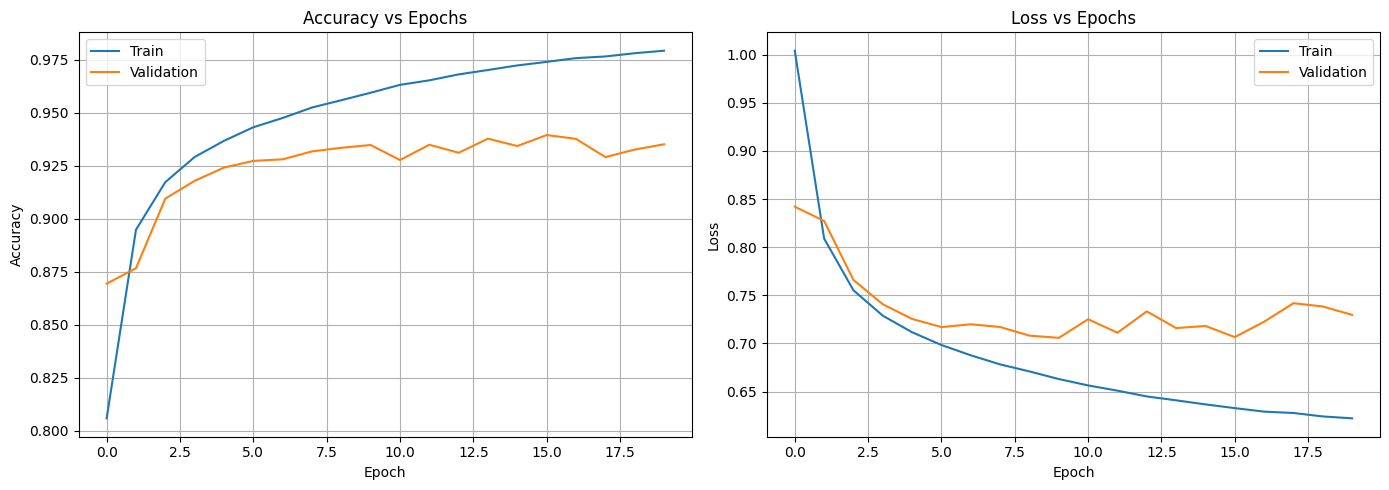

In [14]:
import matplotlib.pyplot as plt

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

axes[0].plot(history.history['accuracy'], label='Train')
axes[0].plot(history.history['val_accuracy'], label='Validation')
axes[0].set_title('Accuracy vs Epochs')
axes[0].set_xlabel('Epoch')
axes[0].set_ylabel('Accuracy')
axes[0].legend()
axes[0].grid(True)

axes[1].plot(history.history['loss'], label='Train')
axes[1].plot(history.history['val_loss'], label='Validation')
axes[1].set_title('Loss vs Epochs')
axes[1].set_xlabel('Epoch')
axes[1].set_ylabel('Loss')
axes[1].legend()
axes[1].grid(True)

plt.tight_layout()
plt.show()

## Confusion Matrix

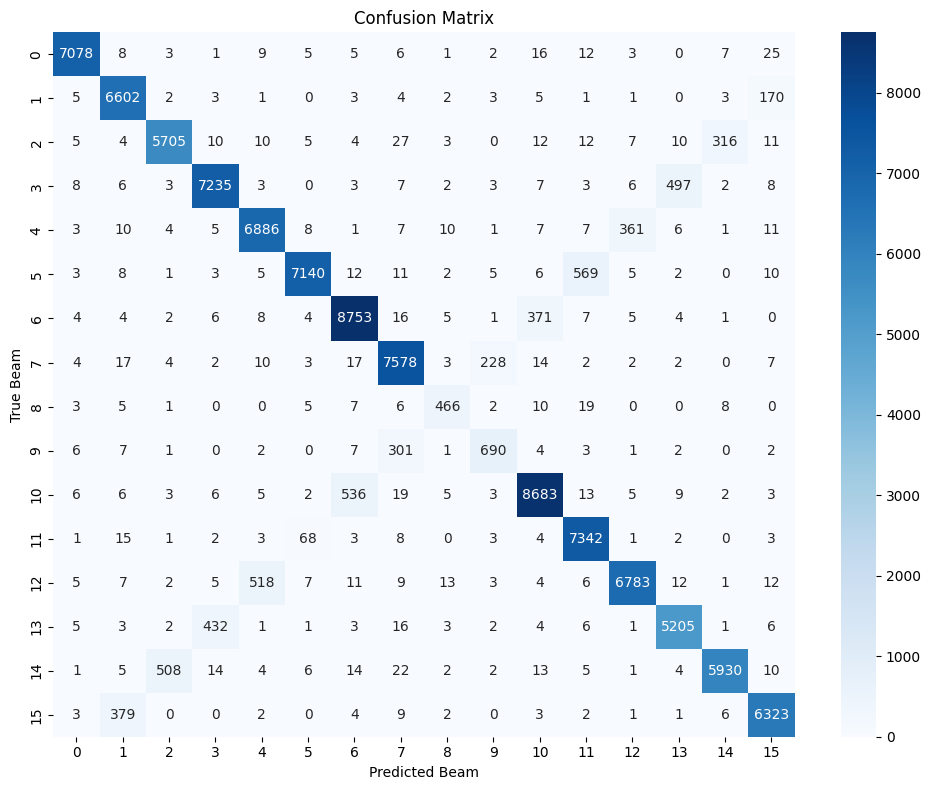


Classification Report:
              precision    recall  f1-score   support

           0       0.99      0.99      0.99      7181
           1       0.93      0.97      0.95      6805
           2       0.91      0.93      0.92      6141
           3       0.94      0.93      0.93      7793
           4       0.92      0.94      0.93      7328
           5       0.98      0.92      0.95      7782
           6       0.93      0.95      0.94      9191
           7       0.94      0.96      0.95      7893
           8       0.90      0.88      0.89       532
           9       0.73      0.67      0.70      1027
          10       0.95      0.93      0.94      9306
          11       0.92      0.98      0.95      7456
          12       0.94      0.92      0.93      7398
          13       0.90      0.91      0.91      5691
          14       0.94      0.91      0.93      6541
          15       0.96      0.94      0.95      6735

    accuracy                           0.94    104800
  

In [15]:
from sklearn.metrics import confusion_matrix, classification_report
import seaborn as sns

y_pred = np.argmax(model.predict(X_test_cnn, verbose=0), axis=1)
y_true = np.argmax(y_test, axis=1)

cm = confusion_matrix(y_true, y_pred)

plt.figure(figsize=(10, 8))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues')
plt.title("Confusion Matrix")
plt.ylabel('True Beam')
plt.xlabel('Predicted Beam')
plt.tight_layout()
plt.show()

print("\nClassification Report:")
print(classification_report(y_true, y_pred))

## Save Model

In [16]:
model.save("beam_selection_improved.keras")
print("Model saved.")

Model saved.


## Prediction Function

In [17]:
def predict_beam(raw_sample_features):
    """
    raw_sample_features: 1D numpy array matching the feature width.
    Returns predicted beam index.
    """
    s = scaler.transform(raw_sample_features.reshape(1, -1))
    s = s.reshape(1, s.shape[1], 1)
    probs = model.predict(s, verbose=0)[0]
    return np.argmax(probs), probs

beam, probs = predict_beam(X_test_raw[0])
print(f"Predicted beam: {beam}, True beam: {y_test_raw[0]}")
print(f"Confidence: {probs[beam]:.4f}")

Predicted beam: 13, True beam: 13
Confidence: 0.9102


## Latency Analysis

In [18]:
import time

N_WARMUP = 100
N_BENCH  = 1000

_ = model.predict(X_test_cnn[:N_WARMUP], verbose=0)  

start = time.perf_counter()
_ = model.predict(X_test_cnn[:N_BENCH], verbose=0)
elapsed = time.perf_counter() - start

print(f"Avg inference time per sample: {elapsed/N_BENCH*1000:.3f} ms")

Avg inference time per sample: 1.639 ms
